In [1]:
import sys

print("Versi Python:", sys.version)
print("Lokasi Python:", sys.executable)

Versi Python: 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]
Lokasi Python: c:\UTS-Graf-Sains-Data-061\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from pathlib import Path

# Jalur dataset
DATA_PATH = Path(r"C:\UTS-Graf-Sains-Data-061\Data\events.csv")

# Periksa keberadaan file
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH}"
    )

# Baca dataset
df = pd.read_csv(DATA_PATH)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)
print("Nama kolom:", df.columns.tolist())

display(df.head())

print("Informasi dataset:")
df.info()

print("\nJumlah nilai kosong:")
display(df.isna().sum())

print("\nJumlah setiap jenis interaksi:")
display(df["event"].value_counts())

print("\nJumlah visitor unik:", df["visitorid"].nunique())
print("Jumlah item unik:", df["itemid"].nunique())

print("\nJumlah baris duplikat:", df.duplicated().sum())

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

print("Tanggal paling awal:", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())
print("Timestamp gagal dikonversi:", df["datetime"].isna().sum())

Dataset berhasil dibaca!
Ukuran dataset: (2756101, 5)
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB

Jumlah nilai kosong:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


Jumlah setiap jenis interaksi:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Jumlah visitor unik: 1407580
Jumlah item unik: 235061

Jumlah baris duplikat: 460
Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00
Timestamp gagal dikonversi: 0


In [3]:

from pathlib import Path
import pandas as pd

# Pastikan kolom datetime tersedia
if "datetime" not in df.columns:
    df["datetime"] = pd.to_datetime(
        df["timestamp"],
        unit="ms",
        errors="coerce",
        utc=True
    )

# Folder penyimpanan hasil
OUTPUT_DIR = Path(r"C:\UTS-Graf-Sains-Data-061\Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Periode 1: 2 Juni sampai 8 Juni 2015
p1 = df[
    (df["datetime"] >= pd.Timestamp("2015-06-02", tz="UTC")) &
    (df["datetime"] < pd.Timestamp("2015-06-09", tz="UTC"))
].copy()

# Periode 2: 8 Agustus sampai 14 Agustus 2015
p2 = df[
    (df["datetime"] >= pd.Timestamp("2015-08-08", tz="UTC")) &
    (df["datetime"] < pd.Timestamp("2015-08-15", tz="UTC"))
].copy()

# Simpan CSV tanpa kolom tambahan datetime
p1.drop(columns=["datetime"], errors="ignore").to_csv(
    OUTPUT_DIR / "P1_training.csv",
    index=False
)

p2.drop(columns=["datetime"], errors="ignore").to_csv(
    OUTPUT_DIR / "P2_testing.csv",
    index=False
)

print("P1 (2–8 Juni 2015):", p1.shape)
print("P2 (8–14 Agustus 2015):", p2.shape)
print("Total data terpilih:", len(p1) + len(p2))
print("Total data awal:", len(df))
print("File tersimpan di:", OUTPUT_DIR)


P1 (2–8 Juni 2015): (144590, 6)
P2 (8–14 Agustus 2015): (118822, 6)
Total data terpilih: 263412
Total data awal: 2756101
File tersimpan di: C:\UTS-Graf-Sains-Data-061\Output


In [4]:
print("Distribusi event Periode 1:")
display(p1["event"].value_counts())

print("Distribusi event Periode 2:")
display(p2["event"].value_counts())

print("Visitor unik P1:", p1["visitorid"].nunique())
print("Visitor unik P2:", p2["visitorid"].nunique())

print("Item unik P1:", p1["itemid"].nunique())
print("Item unik P2:", p2["itemid"].nunique())

Distribusi event Periode 1:


event
view           140000
addtocart        3424
transaction      1166
Name: count, dtype: int64

Distribusi event Periode 2:


event
view           114914
addtocart        3039
transaction       869
Name: count, dtype: int64

Visitor unik P1: 78573
Visitor unik P2: 71310
Item unik P1: 50673
Item unik P2: 46928


In [5]:
from neo4j import GraphDatabase
from getpass import getpass

URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
DATABASE = "uts-gsd26"

PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Python berhasil!")

with driver.session(database=DATABASE) as session:
    result = session.run("RETURN 1 AS koneksi")
    print("Hasil query:", result.single()["koneksi"])

Koneksi Python berhasil!
Hasil query: 1


In [6]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (n)
        RETURN count(n) AS jumlah_node
    """)
    print("Total node:", result.single()["jumlah_node"])

    result = session.run("""
        MATCH ()-[r]->()
        RETURN count(r) AS jumlah_relasi
    """)
    print("Total relasi:", result.single()["jumlah_relasi"])

Total node: 129246
Total relasi: 164590


In [7]:
from pathlib import Path

OUTPUT_DIR = Path(r"C:\UTS-Graf-Sains-Data-061\Output")

file_p1 = OUTPUT_DIR / "P1_training.csv"
file_p2 = OUTPUT_DIR / "P2_testing.csv"

print("P1 tersedia:", file_p1.exists())
print("P2 tersedia:", file_p2.exists())

if file_p1.exists():
    print("Ukuran P1:", file_p1.stat().st_size, "bytes")

if file_p2.exists():
    print("Ukuran P2:", file_p2.stat().st_size, "bytes")

P1 tersedia: True
P2 tersedia: True
Ukuran P1: 5088841 bytes
Ukuran P2: 4183824 bytes


In [8]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        CALL dbms.components()
        YIELD name, versions
        RETURN name, versions
    """)

    for record in result:
        print(record["name"], record["versions"])

Neo4j Kernel ['2026.09.0']
Cypher ['5', '25']


In [9]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(r"C:\UTS-Graf-Sains-Data-061\Output")
FILE_P1 = OUTPUT_DIR / "P1_training.csv"
FILE_P2 = OUTPUT_DIR / "P2_testing.csv"

def import_retailrocket(file_path, period_name, batch_size=5000):
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {file_path}")

    query = """
    UNWIND $rows AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp,
            period: row.period
        }]->(i)
        RETURN 1 AS created

        UNION

        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp,
            period: row.period
        }]->(i)
        RETURN 1 AS created

        UNION

        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionid: row.transactionid,
            period: row.period
        }]->(i)
        RETURN 1 AS created
    }
    RETURN count(*) AS imported
    """

    total_imported = 0

    for chunk in pd.read_csv(file_path, chunksize=batch_size):
        chunk = chunk.astype({
            "timestamp": "int64",
            "visitorid": "int64",
            "itemid": "int64"
        })

        rows = []
        for record in chunk.to_dict(orient="records"):
            transactionid = record["transactionid"]

            rows.append({
                "visitorid": int(record["visitorid"]),
                "itemid": int(record["itemid"]),
                "event": record["event"],
                "timestamp": int(record["timestamp"]),
                "transactionid": (
                    int(transactionid)
                    if pd.notna(transactionid)
                    else None
                ),
                "period": period_name
            })

        with driver.session(database=DATABASE) as session:
            result = session.run(query, rows=rows)
            total_imported += result.single()["imported"]

    print(f"{period_name}: {total_imported:,} interaksi diimpor.")
    return total_imported

In [10]:
print("P1 tersedia:", FILE_P1.exists())
print("P2 tersedia:", FILE_P2.exists())
print("Fungsi impor siap digunakan.")

P1 tersedia: True
P2 tersedia: True
Fungsi impor siap digunakan.


In [14]:

from tqdm.auto import tqdm
import time

# Pastikan lokasi file P1 sudah ditentukan
FILE_P1 = r"C:\UTS-Graf-Sains-Data-061\Output\P1_training.csv"

# Hitung total baris CSV
with open(FILE_P1, "r", encoding="utf-8-sig") as f:
    total_baris_p1 = sum(1 for _ in f) - 1

print(f"Total data P1: {total_baris_p1:,} baris")

# Jalankan import P1 dengan fungsi yang sudah dibuat sebelumnya
total_p1 = import_retailrocket_progress(
    FILE_P1,
    period_name="P1_training",
    batch_size=5000
)

print("Total interaksi P1:", f"{total_p1:,}")


Total data P1: 144,590 baris
Periode       : P1_training
Total baris   : 144,590
Ukuran batch  : 5,000
--------------------------------------------------


Progres Import P1:   0%|          | 0/144590 [00:00<?, ?baris/s]


Import P1 selesai!
Total baris diproses : 144,590
Total interaksi masuk: 144,590
Persentase selesai   : 100.0%
Waktu total          : 6198.3 detik
Total interaksi P1: 144,590


In [11]:
import pandas as pd

with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_node,
               count(n) AS jumlah_node
        ORDER BY jenis_node
    """)

    data_node = [record.data() for record in result]

df_node = pd.DataFrame(data_node)
display(df_node)

,jenis_node,jumlah_node
0,[Item],50673
1,[Visitor],78573


In [12]:
with driver.session(database=DATABASE) as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi,
               count(r) AS jumlah_relasi
        ORDER BY jenis_relasi
    """)

    data_relasi = [record.data() for record in result]

df_relasi = pd.DataFrame(data_relasi)
display(df_relasi)

,jenis_relasi,jumlah_relasi
0,ADDED_TO_CART,3867
1,BOUGHT,1316
2,VIEWED,159407


Shape matriks: (78431, 50574)
Dimensi matriks: 2
Jumlah User: 78431
Jumlah Item: 50574
Jumlah nilai bukan nol: 113099
Total elemen matriks: 3,966,569,394
Jumlah nilai 1: 113,099
Jumlah nilai 0: 3,966,456,295
Sparsity: 99.9971%
Kepadatan matriks: 0.0029%

Informasi Graf Kemiripan User
Jumlah node: 100
Jumlah edge: 498
Jumlah komponen terhubung: 24


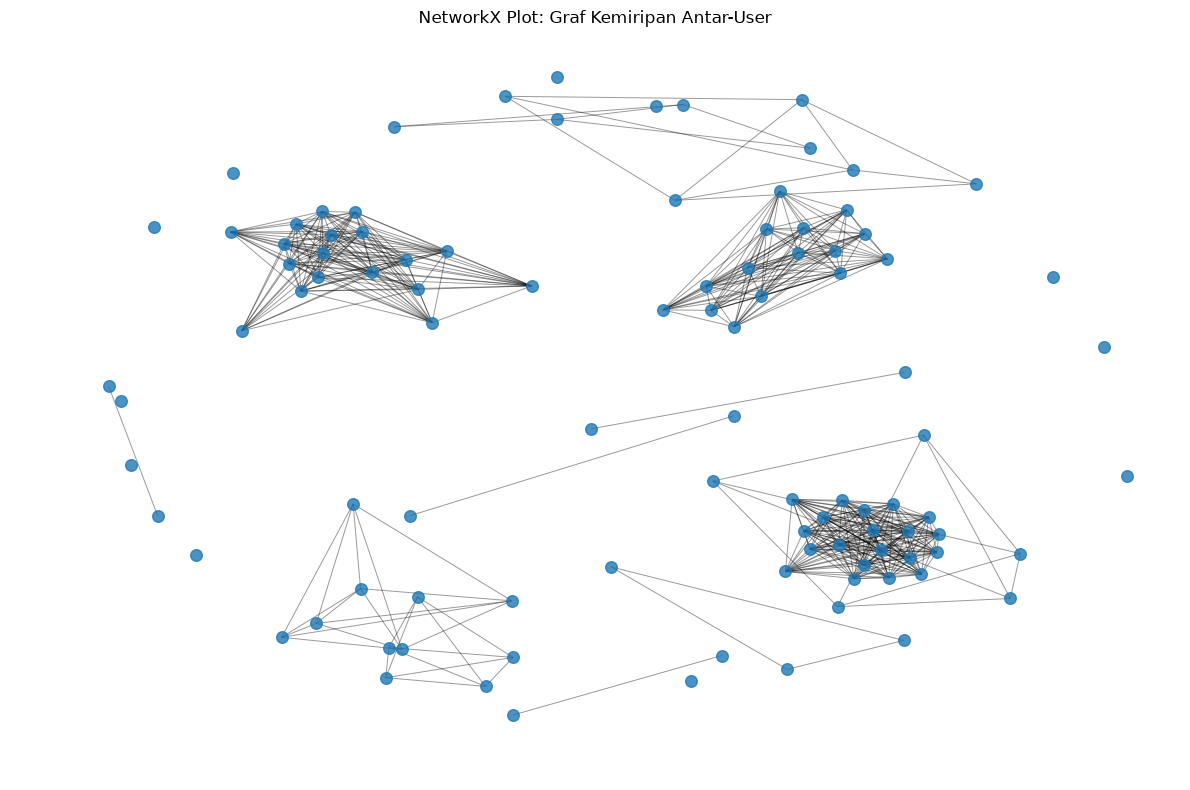

In [17]:
# 2.1 Soal 4 — Vector Space Modelling (VSM) pada Simpul User

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Mengambil data User dan Item dari Neo4j
query_user = """
MATCH (v:Visitor)-[:VIEWED]->(i:Item)
RETURN v.visitorid AS visitorid,
       collect(DISTINCT toString(i.itemid)) AS items
"""

with driver.session(database=DATABASE) as session:
    records_user = [
        record.data()
        for record in session.run(query_user)
    ]

df_vsm_user = pd.DataFrame(records_user)

if df_vsm_user.empty:
    raise ValueError(
        "Data VSM User kosong. Periksa relasi VIEWED di Neo4j."
    )

# 2. Mengubah daftar Item menjadi teks
df_vsm_user["items_text"] = (
    df_vsm_user["items"]
    .apply(lambda items: " ".join(items))
)

# 3. Membentuk matriks VSM User
vectorizer_user = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    binary=True
)

X_user = vectorizer_user.fit_transform(
    df_vsm_user["items_text"]
)

# 4. Menampilkan karakteristik matriks
print("Shape matriks:", X_user.shape)
print("Dimensi matriks:", X_user.ndim)
print("Jumlah User:", X_user.shape[0])
print("Jumlah Item:", X_user.shape[1])
print("Jumlah nilai bukan nol:", X_user.nnz)

# 5. Menghitung sparsity matriks
total_elemen = X_user.shape[0] * X_user.shape[1]
jumlah_nol = total_elemen - X_user.nnz

if total_elemen > 0:
    sparsity = jumlah_nol / total_elemen * 100
    kepadatan = X_user.nnz / total_elemen * 100
else:
    sparsity = 0
    kepadatan = 0

print(f"Total elemen matriks: {total_elemen:,}")
print(f"Jumlah nilai 1: {X_user.nnz:,}")
print(f"Jumlah nilai 0: {jumlah_nol:,}")
print(f"Sparsity: {sparsity:.4f}%")
print(f"Kepadatan matriks: {kepadatan:.4f}%")

# 6. Membentuk graf kemiripan antar-User
# Dibatasi maksimal 100 User agar komputasi lebih ringan
jumlah_user_plot = min(100, X_user.shape[0])

X_sample_user = X_user[:jumlah_user_plot]
user_ids = (
    df_vsm_user["visitorid"]
    .iloc[:jumlah_user_plot]
    .tolist()
)

similarity_user = cosine_similarity(X_sample_user)

G_user = nx.Graph()
G_user.add_nodes_from(user_ids)

threshold = 0.2

for i in range(jumlah_user_plot):
    for j in range(i + 1, jumlah_user_plot):
        nilai = similarity_user[i, j]

        if nilai >= threshold:
            G_user.add_edge(
                user_ids[i],
                user_ids[j],
                weight=float(nilai)
            )

# 7. Menampilkan informasi graf
print("\nInformasi Graf Kemiripan User")
print("Jumlah node:", G_user.number_of_nodes())
print("Jumlah edge:", G_user.number_of_edges())
print(
    "Jumlah komponen terhubung:",
    nx.number_connected_components(G_user)
)

# 8. Visualisasi plot NetworkX
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_user,
    seed=42,
    k=0.5,
    iterations=50
)

nx.draw_networkx_nodes(
    G_user,
    pos,
    node_size=70,
    alpha=0.8
)

nx.draw_networkx_edges(
    G_user,
    pos,
    width=0.7,
    alpha=0.4
)

plt.title("NetworkX Plot: Graf Kemiripan Antar-User")
plt.axis("off")
plt.tight_layout()
plt.show()

Shape matriks: (50574, 78431)
Dimensi matriks: 2
Jumlah Item: 50574
Jumlah Visitor: 78431
Jumlah nilai bukan nol: 113099
Total elemen matriks: 3,966,569,394
Jumlah nilai 1: 113,099
Jumlah nilai 0: 3,966,456,295
Sparsity: 99.9971%
Kepadatan matriks: 0.0029%

Informasi Graf Kemiripan Item
Jumlah node: 100
Jumlah edge: 3
Jumlah komponen terhubung: 97


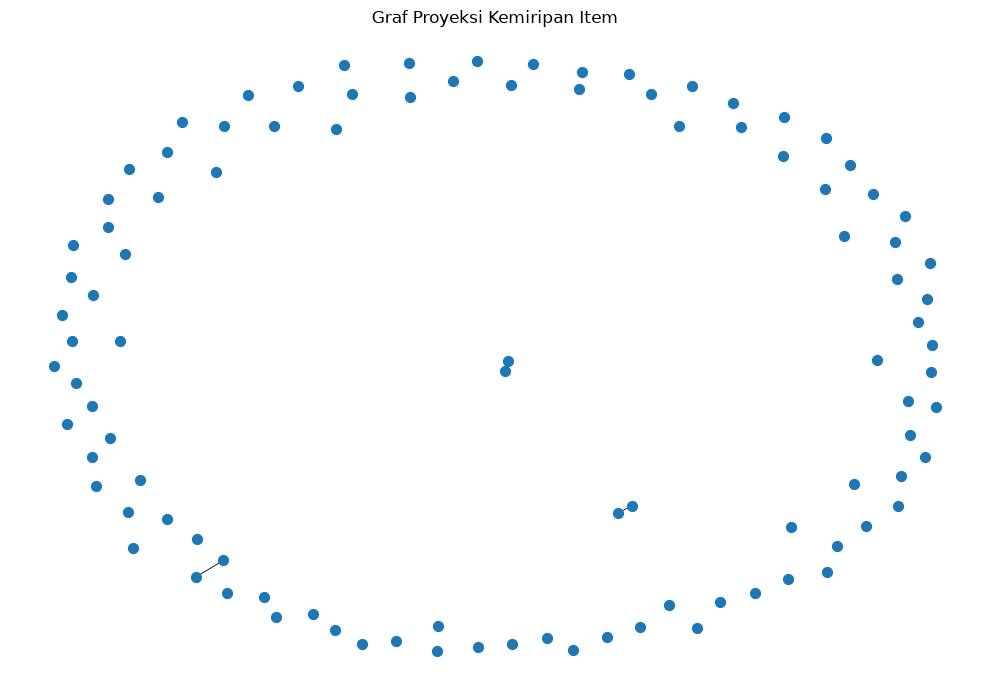

In [14]:
# 2.1 Soal 5 — Vector Space Modelling (VSM) pada Simpul Item

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Mengambil data Item dan Visitor dari Neo4j
query_item = """
MATCH (v:Visitor)-[:VIEWED]->(i:Item)
RETURN i.itemid AS itemid,
       collect(DISTINCT toString(v.visitorid)) AS visitors
"""

with driver.session(database=DATABASE) as session:
    records_item = [
        record.data()
        for record in session.run(query_item)
    ]

df_vsm_item = pd.DataFrame(records_item)

if df_vsm_item.empty:
    raise ValueError(
        "Data VSM Item kosong. Periksa relasi VIEWED di Neo4j."
    )

# Mengubah daftar Visitor menjadi teks
df_vsm_item["visitors_text"] = (
    df_vsm_item["visitors"]
    .apply(lambda visitors: " ".join(visitors))
)

# Membentuk matriks VSM Item
vectorizer_item = CountVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    binary=True
)

X_item = vectorizer_item.fit_transform(
    df_vsm_item["visitors_text"]
)

# Menampilkan informasi matriks
print("Shape matriks:", X_item.shape)
print("Dimensi matriks:", X_item.ndim)
print("Jumlah Item:", X_item.shape[0])
print("Jumlah Visitor:", X_item.shape[1])
print("Jumlah nilai bukan nol:", X_item.nnz)

# Menghitung sparsity matriks
total_elemen = X_item.shape[0] * X_item.shape[1]
jumlah_nol = total_elemen - X_item.nnz

if total_elemen > 0:
    sparsity = jumlah_nol / total_elemen * 100
    kepadatan = X_item.nnz / total_elemen * 100
else:
    sparsity = 0
    kepadatan = 0

print(f"Total elemen matriks: {total_elemen:,}")
print(f"Jumlah nilai 1: {X_item.nnz:,}")
print(f"Jumlah nilai 0: {jumlah_nol:,}")
print(f"Sparsity: {sparsity:.4f}%")
print(f"Kepadatan matriks: {kepadatan:.4f}%")

# Membentuk graf kemiripan antar-Item
jumlah_item_plot = min(100, X_item.shape[0])

X_sample_item = X_item[:jumlah_item_plot]
item_ids = (
    df_vsm_item["itemid"]
    .iloc[:jumlah_item_plot]
    .tolist()
)

similarity_item = cosine_similarity(X_sample_item)

G_item = nx.Graph()
G_item.add_nodes_from(item_ids)

threshold = 0.2

for i in range(jumlah_item_plot):
    for j in range(i + 1, jumlah_item_plot):
        nilai = similarity_item[i, j]

        if nilai >= threshold:
            G_item.add_edge(
                item_ids[i],
                item_ids[j],
                weight=float(nilai)
            )

# Menampilkan informasi graf
print("\nInformasi Graf Kemiripan Item")
print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())
print(
    "Jumlah komponen terhubung:",
    nx.number_connected_components(G_item)
)

# Visualisasi graf menggunakan NetworkX
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=50,
    width=0.6
)

plt.title("Graf Proyeksi Kemiripan Item")
plt.axis("off")
plt.tight_layout()
plt.show()

In [18]:
# 2.1 Soal 6 — Perbandingan Proyeksi User dan Item

import pandas as pd

def ringkasan_proyeksi(nama, X, G):
    total_elemen = X.shape[0] * X.shape[1]
    sparsity = (
        (total_elemen - X.nnz) / total_elemen * 100
        if total_elemen > 0 else 0
    )

    return {
        "Proyeksi": nama,
        "Shape Matriks": str(X.shape),
        "Jumlah Simpul": G.number_of_nodes(),
        "Jumlah Edge": G.number_of_edges(),
        "Jumlah Nilai Bukan Nol": X.nnz,
        "Sparsity (%)": round(sparsity, 4)
    }

hasil_perbandingan = pd.DataFrame([
    ringkasan_proyeksi("User", X_user, G_user),
    ringkasan_proyeksi("Item", X_item, G_item)
])

display(hasil_perbandingan)

,Proyeksi,Shape Matriks,Jumlah Simpul,Jumlah Edge,Jumlah Nilai Bukan Nol,Sparsity (%)
0,User,"(78431, 50574)",100,498,113099,99.9971
1,Item,"(50574, 78431)",100,3,113099,99.9971


In [24]:

# Mencari User yang memiliki similarity positif

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Mengambil sampel 1.000 User secara reproducible
jumlah_sampel = min(1000, X_user.shape[0])

rng = np.random.RandomState(42)
indeks_sampel = np.sort(
    rng.choice(
        X_user.shape[0],
        size=jumlah_sampel,
        replace=False
    )
)

X_sample_user = X_user[indeks_sampel]
user_ids = (
    df_vsm_user["visitorid"]
    .iloc[indeks_sampel]
    .tolist()
)

# Menghitung cosine similarity pada sampel
similarity_matrix = cosine_similarity(X_sample_user)

# Menghitung jumlah pasangan yang memiliki similarity positif
similarity_positif = similarity_matrix.copy()
np.fill_diagonal(similarity_positif, 0)

jumlah_pasangan_positif = (
    similarity_positif > 0
).sum()

print("Jumlah sampel User:", jumlah_sampel)
print(
    "Jumlah pasangan dengan similarity positif:",
    int(jumlah_pasangan_positif)
)

# Mencari User yang memiliki jumlah kemiripan positif terbanyak
jumlah_mirip_per_user = (
    similarity_positif > 0
).sum(axis=1)

indeks_acuan = int(np.argmax(jumlah_mirip_per_user))
user_acuan = user_ids[indeks_acuan]

print("User acuan terpilih:", user_acuan)
print(
    "Jumlah User lain yang mirip:",
    int(jumlah_mirip_per_user[indeks_acuan])
)

# Menampilkan 5 User paling mirip
hasil_similarity = pd.DataFrame({
    "user_acuan": user_acuan,
    "user_lain": user_ids,
    "similarity": similarity_matrix[indeks_acuan]
})

hasil_similarity = hasil_similarity[
    (hasil_similarity["user_lain"] != user_acuan) &
    (hasil_similarity["similarity"] > 0)
].copy()

top_5_similarity = (
    hasil_similarity
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(top_5_similarity)


Jumlah sampel User: 1000
Jumlah pasangan dengan similarity positif: 150
User acuan terpilih: 960004
Jumlah User lain yang mirip: 13


,user_acuan,user_lain,similarity
0,960004,1131518,0.107211
1,960004,460987,0.107211
2,960004,1394314,0.107211
3,960004,431811,0.107211
4,960004,1039649,0.107211


In [25]:

# Soal 7(b) — Menyimpan Top 5 Similarity ke Neo4j

query_simpan_similarity = """
MATCH (a:Visitor {visitorid: $user_acuan})
MATCH (b:Visitor {visitorid: $user_lain})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = $similarity
RETURN
    a.visitorid AS user_acuan,
    b.visitorid AS user_lain,
    r.similarity AS similarity
"""

data_similarity = top_5_similarity.to_dict(orient="records")

with driver.session(database=DATABASE) as session:
    hasil_simpan = []

    for row in data_similarity:
        result = session.run(
            query_simpan_similarity,
            user_acuan=int(row["user_acuan"]),
            user_lain=int(row["user_lain"]),
            similarity=float(row["similarity"])
        )
        hasil_simpan.extend(record.data() for record in result)

df_hasil_simpan = pd.DataFrame(hasil_simpan)
display(df_hasil_simpan)


,user_acuan,user_lain,similarity
0,960004,1131518,0.107211
1,960004,460987,0.107211
2,960004,1394314,0.107211
3,960004,431811,0.107211
4,960004,1039649,0.107211


In [49]:

# Memverifikasi Top 5 Similarity di Neo4j

query_verifikasi = """
MATCH (a:Visitor {visitorid: 960004})-[r:SIMILAR_TO]->(b:Visitor)
RETURN
    a.visitorid AS user_acuan,
    b.visitorid AS user_lain,
    r.similarity AS similarity
ORDER BY r.similarity DESC, b.visitorid ASC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    hasil_verifikasi = [
        record.data()
        for record in session.run(query_verifikasi)
    ]

df_verifikasi = pd.DataFrame(hasil_verifikasi)
display(df_verifikasi)


,user_acuan,user_lain,similarity
0,960004,431811,0.107211
1,960004,460987,0.107211
2,960004,1039649,0.107211
3,960004,1131518,0.107211
4,960004,1394314,0.107211


**2.2**


In [50]:
# Membuat daftar User dan Item dari data training
daftar_user = np.sort(train_interaksi["visitorid"].unique())
daftar_item = np.sort(train_interaksi["itemid"].unique())

# Membuat pemetaan ID ke indeks matriks
user_to_idx = {user: idx for idx, user in enumerate(daftar_user)}
item_to_idx = {item: idx for idx, item in enumerate(daftar_item)}

# Mengubah ID User dan Item menjadi indeks
baris = train_interaksi["visitorid"].map(user_to_idx).to_numpy()
kolom = train_interaksi["itemid"].map(item_to_idx).to_numpy()

# Matriks interaksi biner
X = csr_matrix(
    (
        np.ones(len(train_interaksi), dtype=np.float32),
        (baris, kolom)
    ),
    shape=(len(daftar_user), len(daftar_item))
)

print("Shape matriks User-Item:", X.shape)

Shape matriks User-Item: (78573, 50673)


In [51]:
# Memilih User yang tersedia pada kedua periode
user_training = set(train_interaksi["visitorid"].unique())
user_testing = set(test_interaksi["visitorid"].unique())

user_bersama = sorted(user_training.intersection(user_testing))

if len(user_bersama) == 0:
    raise ValueError(
        "Tidak ada User yang muncul di kedua periode. "
        "Periksa kembali file training dan testing."
    )

# Pemilihan acak yang dapat direproduksi
rng = np.random.RandomState(42)
user_target = int(rng.choice(user_bersama))

print("User terpilih:", user_target)

# Mengambil baris matriks untuk User target
idx_target = user_to_idx[user_target]
vektor_target = X[idx_target]

# Menghitung cosine similarity terhadap semua User
skor_similarity = cosine_similarity(
    vektor_target,
    X
).ravel()

# User tidak boleh menjadi tetangganya sendiri
skor_similarity[idx_target] = -1

# Mengambil 5 tetangga terdekat
k = 5
idx_tetangga = np.argsort(-skor_similarity)[:k]

tetangga = pd.DataFrame({
    "visitorid": daftar_user[idx_tetangga],
    "similarity": skor_similarity[idx_tetangga]
})

display(tetangga)

User terpilih: 252016


,visitorid,similarity
0,1154422,1.0
1,926082,1.0
2,715736,1.0
3,699254,1.0
4,1407432,0.0


In [52]:
# Menghitung skor item dari 5 tetangga terdekat
skor_item = np.zeros(len(daftar_item), dtype=float)

for idx in idx_tetangga:
    if skor_similarity[idx] > 0:
        skor_item += skor_similarity[idx] * X[idx].toarray().ravel()

# Mengeluarkan item yang sudah pernah dilihat/diinteraksikan User target
item_pernah = set(
    train_interaksi.loc[
        train_interaksi["visitorid"] == user_target,
        "itemid"
    ]
)

for item, idx in item_to_idx.items():
    if item in item_pernah:
        skor_item[idx] = -1

# Mengambil 5 rekomendasi teratas
idx_rekomendasi = np.argsort(-skor_item)[:5]

rekomendasi_top5 = pd.DataFrame({
    "peringkat": range(1, 6),
    "itemid": daftar_item[idx_rekomendasi],
    "skor_rekomendasi": skor_item[idx_rekomendasi]
})

# Hanya item dengan skor positif yang dianggap rekomendasi valid
rekomendasi_top5 = rekomendasi_top5[
    rekomendasi_top5["skor_rekomendasi"] > 0
].reset_index(drop=True)

rekomendasi_top5["peringkat"] = range(1, len(rekomendasi_top5) + 1)

print("Lima rekomendasi teratas:")
display(rekomendasi_top5)

print("Tiga item teratas sesuai permintaan soal:")
display(rekomendasi_top5.head(3))

Lima rekomendasi teratas:


,peringkat,itemid,skor_rekomendasi


Tiga item teratas sesuai permintaan soal:


,peringkat,itemid,skor_rekomendasi


In [53]:
# Mengambil item aktual User target dari data testing
item_aktual = set(
    test_interaksi.loc[
        test_interaksi["visitorid"] == user_target,
        "itemid"
    ]
)

# Daftar item rekomendasi maksimal 5
daftar_rekomendasi = rekomendasi_top5["itemid"].head(5).tolist()

# Hit@5
hit = int(
    any(item in item_aktual for item in daftar_rekomendasi)
)

# NDCG@5 dengan relevansi biner
relevansi = [
    1 if item in item_aktual else 0
    for item in daftar_rekomendasi
]

dcg = sum(
    rel / np.log2(posisi + 1)
    for posisi, rel in enumerate(relevansi, start=1)
)

jumlah_relevan = min(5, len(item_aktual))

ideal_relevansi = [1] * jumlah_relevan
idcg = sum(
    rel / np.log2(posisi + 1)
    for posisi, rel in enumerate(ideal_relevansi, start=1)
)

ndcg = dcg / idcg if idcg > 0 else 0.0

print("User target:", user_target)
print("Jumlah item aktual pada testing:", len(item_aktual))
print("Item rekomendasi:", daftar_rekomendasi)
print("Item relevan pada rekomendasi:", [
    item for item in daftar_rekomendasi if item in item_aktual
])
print("Hit@5:", hit)
print("NDCG@5:", round(ndcg, 4))

User target: 252016
Jumlah item aktual pada testing: 1
Item rekomendasi: []
Item relevan pada rekomendasi: []
Hit@5: 0
NDCG@5: 0.0


In [54]:
import numpy as np

# Relevansi tiap item rekomendasi: 1 jika cocok, 0 jika tidak
relevansi = [
    1 if item in item_aktual else 0
    for item in daftar_rekomendasi
]

# Menghitung DCG@5
dcg_at_5 = sum(
    rel / np.log2(posisi + 1)
    for posisi, rel in enumerate(relevansi, start=1)
)

# Menghitung IDCG@5
jumlah_relevan = min(5, len(item_aktual))

idcg_at_5 = sum(
    1 / np.log2(posisi + 1)
    for posisi in range(1, jumlah_relevan + 1)
)

# Menghitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("Relevansi:", relevansi)
print("DCG@5 =", round(dcg_at_5, 4))
print("IDCG@5 =", round(idcg_at_5, 4))
print("NDCG@5 =", round(ndcg_at_5, 4))

Relevansi: []
DCG@5 = 0
IDCG@5 = 1.0
NDCG@5 = 0.0
